# AIFUL 12-Month Default — Honest CV (standalone)



- โหลดข้อมูลและตรวจ schema
- Feature engineering
- Fold-safe target encoding
- LightGBM / CatBoost พร้อม inner early stopping
- Outer 5-fold CV สำหรับวัดผลแบบ honest
- Seed averaging, rank-average blending, bootstrap CI
- Calibration + threshold + submission


## Output

- `honest_v3_outputs/submission_honest_v3_proba.csv`
- `honest_v3_outputs/submission_honest_v3_label_youden.csv`
- `honest_v3_outputs/submission_honest_v3_label_rate.csv`
- `honest_v3_outputs/metrics.json`
- `honest_v3_outputs/run_config.json`
- `honest_v3_outputs/artifacts/*`

หมายเหตุ: **Validation** ในที่นี้คือ OOF prediction จาก outer folds ไม่ใช่ holdout แยก

Runtime โดยประมาณ: 5–8 นาที (5 folds, 1 seed, 3 models) บน CPU

In [8]:
import itertools
import json
import sys
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from types import SimpleNamespace
from typing import Any, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)

import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

try:
    from catboost import CatBoostClassifier

    CATBOOST_AVAILABLE = True
except ImportError:
    CatBoostClassifier = None
    CATBOOST_AVAILABLE = False

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("LightGBM    :", lgb.__version__)
print("CatBoost    :", "available" if CATBOOST_AVAILABLE else "not installed")

Python      : 3.13.8
NumPy       : 2.5.4
pandas      : 3.1.1
scikit-learn: 1.9.1
LightGBM    : 4.7.0
CatBoost    : available


## 1. ตั้งค่า

แก้ค่าที่นี่ที่เดียว

- `MODELS`: `lgb_fe`, `lgb_te`, `cat` (เพิ่ม `lgb_raw` ได้)
- `N_FOLDS`, `SEEDS`: จำนวน outer folds และ seeds ที่ใช้ averaging
- `FAST=True`: smoke test (3 folds, 1 seed, ES 100, bootstrap 200)
- `SAVE=False`: คำนวณผลแต่ไม่เขียนไฟล์

In [9]:
def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data" / "train_dataset.csv").exists():
            return candidate
    return start


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data"
OUT_DIR = PROJECT_ROOT / "honest_v3_outputs"

MODELS = ["lgb_fe", "lgb_te", "cat"]
N_FOLDS = 5
SEEDS = [42]
INNER_SIZE = 0.15
ES_ROUNDS = 200
TE_SMOOTH = 20.0
TE_INNER_FOLDS = 5
BLEND = "auto"
BLEND_STEP = 0.05
BOOTSTRAP = 1000
CALIBRATE = True
SAVE = True
FAST = False
SEED = 42
N_JOBS = -1
LGB_ESTIMATORS = 6000
CAT_ITERATIONS = 3000

if FAST:
    N_FOLDS = min(N_FOLDS, 3)
    SEEDS = [42]
    ES_ROUNDS = min(ES_ROUNDS, 100)
    TE_INNER_FOLDS = min(TE_INNER_FOLDS, 3)
    BOOTSTRAP = min(BOOTSTRAP, 200)

CFG = SimpleNamespace(
    n_folds=N_FOLDS,
    seeds=SEEDS,
    inner_size=INNER_SIZE,
    es_rounds=ES_ROUNDS,
    te_smooth=TE_SMOOTH,
    te_inner_folds=TE_INNER_FOLDS,
    blend=BLEND,
    blend_step=BLEND_STEP,
    bootstrap=BOOTSTRAP,
    calibrate=CALIBRATE,
    save=SAVE,
    seed=SEED,
    n_jobs=N_JOBS,
    lgb_estimators=LGB_ESTIMATORS,
    cat_iterations=CAT_ITERATIONS,
)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"ไม่พบ data directory: {DATA_DIR}")
if OUT_DIR.resolve() == DATA_DIR.resolve() or DATA_DIR.resolve() in OUT_DIR.resolve().parents:
    raise ValueError("OUT_DIR ต้องไม่อยู่ใน DATA_DIR")
if CFG.n_folds < 2:
    raise ValueError("N_FOLDS ต้องมีอย่างน้อย 2")
if not CFG.seeds:
    raise ValueError("SEEDS ต้องมีอย่างน้อย 1")
if not 0.0 < CFG.inner_size < 0.5:
    raise ValueError("INNER_SIZE ต้องอยู่ระหว่าง 0 และ 0.5")
if CFG.te_smooth < 0:
    raise ValueError("TE_SMOOTH ต้องไม่ติดลบ")
if CFG.te_inner_folds < 2:
    raise ValueError("TE_INNER_FOLDS ต้องมีอย่างน้อย 2")
if CFG.es_rounds < 1:
    raise ValueError("ES_ROUNDS ต้องมีอย่างน้อย 1")
if CFG.bootstrap < 0:
    raise ValueError("BOOTSTRAP ต้องไม่ติดลบ")
if not 0.0 < CFG.blend_step <= 0.5:
    raise ValueError("BLEND_STEP ต้องอยู่ระหว่าง 0 และ 0.5")
if CFG.lgb_estimators < 1 or CFG.cat_iterations < 1:
    raise ValueError("จำนวน estimators ต้องมากกว่า 0")

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR    :", DATA_DIR)
print("OUT_DIR     :", OUT_DIR)
print("MODELS      :", MODELS)
print("N_FOLDS     :", CFG.n_folds)
print("SEEDS       :", CFG.seeds)
print("FAST        :", FAST)
print("SAVE        :", CFG.save)
print("CALIBRATE   :", CFG.calibrate)
print("BOOTSTRAP   :", CFG.bootstrap)

PROJECT_ROOT: C:\Users\ice55\Downloads\Aihack Thailand 2026
DATA_DIR    : C:\Users\ice55\Downloads\Aihack Thailand 2026\data
OUT_DIR     : C:\Users\ice55\Downloads\Aihack Thailand 2026\honest_v3_outputs
MODELS      : ['lgb_fe', 'lgb_te', 'cat']
N_FOLDS     : 5
SEEDS       : [42]
FAST        : False
SAVE        : True
CALIBRATE   : True
BOOTSTRAP   : 1000


## 2. โหลดข้อมูลและตรวจ schema

ไฟล์ต้นฉบับถูกอ่านอย่างเดียว ไม่มีการแก้ไข

In [10]:
ID_COL = "ID"
TARGET = "12-Month Default Flag"

CAT_COLS = [
    "Application Channel",
    "Marital Status",
    "Occupation Category",
    "Industry Category",
    "Employment Type Category",
    "Insurance Type",
    "Company Size Category",
    "Business Entity Type",
    "Residence Type",
    "Residence Ownership Status",
]

PHONE_COLS = [
    "Home Phone Number Available",
    "Mobile Phone Number Available",
    "Employer Phone Number Available",
    "Driver Licence Number Available",
]

RAW_FEATURES = [
    "Application Channel",
    "Gender",
    "Marital Status",
    "Age (in months)",
    "Residence Period (in months)",
    "Occupation Category",
    "Industry Category",
    "Employment Type Category",
    "Insurance Type",
    "Company Size Category",
    "Business Entity Type",
    "Declared Annual Income",
    "Payday",
    "Declared Number of Borrowings",
    "Declared Borrowing Amount",
    "Desired Credit Limit",
    "Residence Type",
    "Rent Burden",
    "Residence Ownership Status",
    "Number of Dependents",
    "Number of Dependent Children",
    "Home Phone Number Available",
    "Mobile Phone Number Available",
    "Employer Phone Number Available",
    "Driver Licence Number Available",
]

ALL_MODELS = ("lgb_raw", "lgb_fe", "lgb_te", "cat")

MODEL_DESCRIPTIONS = {
    "lgb_raw": "LightGBM บน 25 raw application columns",
    "lgb_fe": "LightGBM บน raw + engineered features",
    "lgb_te": "LightGBM บน raw + engineered + fold-safe target encoding",
    "cat": "CatBoost บน raw + engineered features",
}

PRIOR_WEIGHTS = {
    "cat": 0.50,
    "lgb_fe": 0.30,
    "lgb_te": 0.25,
    "lgb_raw": 0.20,
}

unknown_models = sorted(set(MODELS) - set(ALL_MODELS))
if unknown_models:
    raise ValueError(f"Unknown model(s): {unknown_models}; choose from {ALL_MODELS}")
if "cat" in MODELS and not CATBOOST_AVAILABLE:
    raise ImportError("MODELS มี 'cat' แต่ยังไม่ได้ติดตั้ง CatBoost")


def load_data(data_dir: Path):
    paths = {
        "train": data_dir / "train_dataset.csv",
        "test": data_dir / "test_without_gt.csv",
        "template": data_dir / "submission_template_for_test.csv",
    }
    missing = [str(path) for path in paths.values() if not path.exists()]
    if missing:
        raise FileNotFoundError("Missing input file(s): " + ", ".join(missing))
    train = pd.read_csv(paths["train"])
    test = pd.read_csv(paths["test"])
    template = pd.read_csv(paths["template"])
    validate_raw_data(train, test, template)
    return train, test, template


def validate_raw_data(
    train: pd.DataFrame,
    test: pd.DataFrame,
    template: pd.DataFrame,
) -> None:
    expected_train = {ID_COL, TARGET, *RAW_FEATURES}
    expected_test = {ID_COL, *RAW_FEATURES}
    if set(train.columns) != expected_train:
        missing = sorted(expected_train - set(train.columns))
        extra = sorted(set(train.columns) - expected_train)
        raise ValueError(f"Unexpected train schema; missing={missing}, extra={extra}")
    if set(test.columns) != expected_test:
        missing = sorted(expected_test - set(test.columns))
        extra = sorted(set(test.columns) - expected_test)
        raise ValueError(f"Unexpected test schema; missing={missing}, extra={extra}")
    if set(template.columns) != {ID_COL, TARGET}:
        raise ValueError("Submission template must have exactly ID and target columns")
    if not train[ID_COL].is_unique or not test[ID_COL].is_unique:
        raise ValueError("Train and test IDs must be unique")
    if set(train[ID_COL]) & set(test[ID_COL]):
        raise ValueError("Train and test IDs overlap")
    if not template[ID_COL].is_unique:
        raise ValueError("Template IDs must be unique")
    if set(template[ID_COL]) != set(test[ID_COL]):
        raise ValueError("Template IDs do not match test IDs")
    if train[TARGET].isna().any():
        raise ValueError("Train target contains missing values")
    if not set(train[TARGET].astype(int).unique()).issubset({0, 1}):
        raise ValueError("Train target must be binary")


train, test, template = load_data(DATA_DIR)
print(f"train {train.shape} | test {test.shape} | template {template.shape}")
print(f"default rate (train) = {train[TARGET].mean():.4%}")

train (68546, 27) | test (137091, 26) | template (137091, 2)
default rate (train) = 9.6767%


## 3. Feature engineering

สร้าง deterministic features จากข้อมูล application:

- log ของเงินก้อนใหญ่
- affordability ratios (debt/income, limit/income, rent/income)
- debt structure (borrow/limit, average loan)
- stability (residence period เทียบอายุ, residence gap)
- payday encoding
- outlier flags
- frequency ของ categorical columns

Frequency features ใช้ train+test แต่ไม่ใช้ target จึงไม่เป็น target leakage

In [11]:
def safe_div(a: pd.Series, b: pd.Series) -> pd.Series:
    b = b.astype(float)
    return a.astype(float) / b.where(b > 0)


def add_engineered_features(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    inc = d["Declared Annual Income"].astype(float)
    debt = d["Declared Borrowing Amount"].astype(float)
    lim = d["Desired Credit Limit"].astype(float)
    rent = d["Rent Burden"].astype(float)
    ndep = d["Number of Dependents"].astype(float)
    nchild = d["Number of Dependent Children"].astype(float)
    age = d["Age (in months)"].astype(float)
    res = d["Residence Period (in months)"].astype(float)
    nbor = d["Declared Number of Borrowings"].astype(float)
    payday = d["Payday"].astype(float)

    for name, series in (
        ("log_income", inc),
        ("log_debt", debt),
        ("log_limit", lim),
        ("log_rent", rent),
    ):
        d[name] = np.log1p(np.clip(series, 0, None))

    d["income_month"] = inc / 12.0
    d["disposable_month"] = inc / 12.0 - rent
    d["borrow_to_income"] = safe_div(debt, inc)
    d["limit_to_income"] = safe_div(lim, inc)
    d["total_to_income"] = safe_div(debt + lim, inc)
    d["borrow_to_limit"] = safe_div(debt, lim)
    d["avg_loan"] = safe_div(debt, nbor)
    d["rent_to_income"] = safe_div(rent, inc / 12.0)
    d["income_per_dep"] = inc / (ndep + 1.0)
    d["children_share"] = safe_div(nchild, ndep)

    d["residence_ratio"] = safe_div(res, age)
    d["age_years"] = age / 12.0
    d["residence_years"] = res / 12.0
    d["phone_count"] = d[PHONE_COLS].sum(axis=1)

    for col in (
        "borrow_to_income",
        "limit_to_income",
        "total_to_income",
        "borrow_to_limit",
        "avg_loan",
        "rent_to_income",
        "income_per_dep",
    ):
        d["log_" + col] = np.log1p(np.clip(d[col], 0, None))

    d["residence_gap"] = age - res
    d["residence_gap_ratio"] = safe_div(age - res, age)
    d["same_address_since_birth"] = (res >= age).astype(int)

    d["payday_sin"] = np.sin(2.0 * np.pi * payday / 31.0)
    d["payday_cos"] = np.cos(2.0 * np.pi * payday / 31.0)
    d["payday_end"] = ((payday >= 28) & (payday <= 31)).astype(int)
    d["payday_25"] = (payday == 25).astype(int)
    d["payday_31"] = (payday == 31).astype(int)

    d["income_gt_1b"] = (inc > 1e9).astype(int)
    d["debt_gt_1b"] = (debt > 1e9).astype(int)
    d["rent_gt_10m"] = (rent > 1e7).astype(int)
    d["nonpositive_income"] = (inc <= 0).astype(int)
    d["outlier_count"] = d[
        ["income_gt_1b", "debt_gt_1b", "rent_gt_10m", "nonpositive_income"]
    ].sum(axis=1)

    d["debt_per_dep"] = safe_div(debt, ndep + 1.0)
    d["rent_per_dep"] = safe_div(rent, ndep + 1.0)
    d["disposable_per_dep"] = safe_div(d["disposable_month"], ndep + 1.0)
    d["log_income_minus_log_debt"] = d["log_income"] - d["log_debt"]
    d["log_income_minus_log_rent"] = d["log_income"] - d["log_rent"]
    d["borrow_to_income_x_age"] = d["borrow_to_income"] * d["age_years"]
    d["income_covers_debt"] = (inc >= debt).astype(int)

    return d.replace([np.inf, -np.inf], np.nan)


def add_frequency_features(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    for col in CAT_COLS:
        counts = d[col].value_counts(dropna=False)
        d[f"freq__{col}"] = d[col].map(counts).astype(float)
    return d

## 4. เตรียมข้อมูล

รวม train+test เพื่อให้ categorical categories และ frequency ตรงกัน
แล้วแยกกลับเป็น `X_train`, `X_test`, `y`

In [12]:
@dataclass
class PreparedData:
    X_train: pd.DataFrame
    X_test: pd.DataFrame
    y: np.ndarray
    train_ids: pd.Series
    test_ids: pd.Series
    template: pd.DataFrame
    raw_features: list[str]
    engineered_features: list[str]
    all_features: list[str]
    cat_features: list[str]


def prepare_data(
    train: pd.DataFrame,
    test: pd.DataFrame,
    template: pd.DataFrame,
) -> PreparedData:
    y = train[TARGET].astype(int).to_numpy()
    full = pd.concat([train.drop(columns=[TARGET]), test], ignore_index=True)
    full = add_engineered_features(full)
    full = add_frequency_features(full)
    for col in CAT_COLS:
        full[col] = full[col].astype("category")

    feature_names = [col for col in full.columns if col != ID_COL]
    raw_features = [col for col in feature_names if col in RAW_FEATURES]
    engineered_features = [col for col in feature_names if col not in RAW_FEATURES]
    n_train = len(train)
    X_train = full.iloc[:n_train][feature_names].reset_index(drop=True)
    X_test = full.iloc[n_train:][feature_names].reset_index(drop=True)

    if len(X_test) != len(template):
        raise ValueError("Test row count does not match submission template")

    return PreparedData(
        X_train=X_train,
        X_test=X_test,
        y=y,
        train_ids=train[ID_COL].reset_index(drop=True),
        test_ids=test[ID_COL].reset_index(drop=True),
        template=template.reset_index(drop=True),
        raw_features=raw_features,
        engineered_features=engineered_features,
        all_features=feature_names,
        cat_features=list(CAT_COLS),
    )


data = prepare_data(train, test, template)
print(f"raw_features={len(data.raw_features)}")
print(f"engineered_features={len(data.engineered_features)}")
print(f"total_features={len(data.all_features)}")
print(f"n_train={len(data.X_train):,} | n_test={len(data.X_test):,}")

raw_features=25
engineered_features=55
total_features=80
n_train=68,546 | n_test=137,091


## 5. Target encoding แบบ fold-safe

สำหรับแต่ละ categorical column:

- ค่า encoding ของแถวใน training ใช้ inner-fold OOF
- validation/test ใช้ mapping จาก training fold เท่านั้น
- ใช้ smoothing เพื่อกัน category ที่มี sample น้อย

Target statistics ของ validation/test จะไม่ถูกใช้ในการ fit

In [13]:
def _te_map(
    keys: pd.Series,
    y: np.ndarray,
    global_mean: float,
    smooth: float,
) -> pd.Series:
    frame = pd.DataFrame(
        {"key": keys.to_numpy(), "target": np.asarray(y, dtype=float)}
    )
    stats = frame.groupby("key")["target"].agg(["mean", "count"])
    return (stats["mean"] * stats["count"] + global_mean * smooth) / (
        stats["count"] + smooth
    )


def fit_target_encoding(
    train_df: pd.DataFrame,
    y_train: np.ndarray,
    apply_dfs: Sequence[pd.DataFrame],
    cat_cols: Sequence[str],
    smooth: float,
    inner_folds: int,
    seed: int,
) -> tuple[pd.DataFrame, list[pd.DataFrame]]:
    y = np.asarray(y_train, dtype=int)
    global_mean = float(y.mean())
    train_out = pd.DataFrame(index=train_df.index)
    apply_out = [pd.DataFrame(index=df.index) for df in apply_dfs]
    min_class = int(pd.Series(y).value_counts().min()) if len(y) else 0
    n_splits = min(inner_folds, min_class)

    for col in cat_cols:
        keys = train_df[col].astype(object)
        oof = pd.Series(np.nan, index=train_df.index, dtype=float)

        if n_splits >= 2:
            splitter = StratifiedKFold(
                n_splits=n_splits,
                shuffle=True,
                random_state=seed,
            )
            for fit_idx, val_idx in splitter.split(train_df, y):
                fit_mean = float(y[fit_idx].mean())
                encoding = _te_map(keys.iloc[fit_idx], y[fit_idx], fit_mean, smooth)
                mapped = keys.iloc[val_idx].map(encoding)
                oof.iloc[val_idx] = mapped.fillna(fit_mean).to_numpy()
        else:
            encoding = _te_map(keys, y, global_mean, smooth)
            oof = keys.map(encoding).fillna(global_mean)

        full_encoding = _te_map(keys, y, global_mean, smooth)
        train_out[f"te__{col}"] = oof.fillna(global_mean).to_numpy()
        for out, frame in zip(apply_out, apply_dfs):
            out[f"te__{col}"] = (
                frame[col]
                .astype(object)
                .map(full_encoding)
                .fillna(global_mean)
                .to_numpy()
            )

    return train_out, apply_out

## 6. ฟังก์ชันฝึกโมเดล

แต่ละ fold:

1. แบ่ง inner fit / inner validation จาก outer training fold
2. ฝึกด้วย early stopping บน inner validation
3. ได้ `best_iteration`
4. Refit บน outer training fold ทั้งก้อนด้วย `best_iteration`
5. ทำนาย outer validation และ test

จากนั้นเฉลี่ย prediction ข้าม seeds

In [14]:
@dataclass
class ExperimentResult:
    name: str
    oof: np.ndarray
    test_pred: np.ndarray
    fold_aucs: list[float]
    best_iterations: list[int]
    fold_scores: list[dict[str, Any]]
    feature_importance: pd.Series | None
    n_features: int
    elapsed_sec: float


LGB_PARAMS = dict(
    n_estimators=6000,
    learning_rate=0.02,
    num_leaves=15,
    min_child_samples=500,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.6,
    reg_lambda=10.0,
    cat_smooth=200,
    min_data_per_group=200,
    verbose=-1,
)

CAT_PARAMS = dict(
    iterations=3000,
    learning_rate=0.03,
    depth=6,
    l2_leaf_reg=30,
    eval_metric="AUC",
    cat_features=CAT_COLS,
    one_hot_max_size=20,
    rsm=0.8,
    bootstrap_type="Bernoulli",
    subsample=0.8,
    max_ctr_complexity=1,
    verbose=0,
    allow_writing_files=False,
)


def cat_frame(df: pd.DataFrame, cat_cols: Sequence[str]) -> pd.DataFrame:
    out = df.copy()
    for col in cat_cols:
        out[col] = out[col].astype(str)
    return out


def fit_lgb(
    features: list[str],
    cat_features: list[str],
    inner_fit: pd.DataFrame,
    inner_y: np.ndarray,
    inner_valid: pd.DataFrame,
    inner_valid_y: np.ndarray,
    outer: pd.DataFrame,
    outer_y: np.ndarray,
    outer_valid: pd.DataFrame,
    test: pd.DataFrame,
    seed: int,
    es_rounds: int,
    n_estimators: int,
    n_jobs: int,
) -> tuple[np.ndarray, np.ndarray, int, np.ndarray]:
    base_params = {
        **LGB_PARAMS,
        "n_estimators": n_estimators,
        "random_state": seed,
        "n_jobs": n_jobs,
    }
    inner_model = lgb.LGBMClassifier(**base_params)
    inner_model.fit(
        inner_fit[features],
        inner_y,
        eval_set=[(inner_valid[features], inner_valid_y)],
        eval_metric="auc",
        categorical_feature=cat_features,
        callbacks=[lgb.early_stopping(es_rounds, verbose=False)],
    )
    best_iteration = int(inner_model.best_iteration_ or n_estimators)

    final_params = {**base_params, "n_estimators": max(1, best_iteration)}
    final_model = lgb.LGBMClassifier(**final_params)
    final_model.fit(
        outer[features],
        outer_y,
        categorical_feature=cat_features,
    )
    valid_pred = final_model.predict_proba(outer_valid[features])[:, 1]
    test_pred = final_model.predict_proba(test[features])[:, 1]
    importance = np.asarray(final_model.feature_importances_, dtype=float)
    return valid_pred, test_pred, best_iteration, importance


def fit_cat(
    features: list[str],
    cat_features: list[str],
    inner_fit: pd.DataFrame,
    inner_y: np.ndarray,
    inner_valid: pd.DataFrame,
    inner_valid_y: np.ndarray,
    outer: pd.DataFrame,
    outer_y: np.ndarray,
    outer_valid: pd.DataFrame,
    test: pd.DataFrame,
    seed: int,
    es_rounds: int,
    iterations: int,
    n_jobs: int,
) -> tuple[np.ndarray, np.ndarray, int, np.ndarray]:
    if CatBoostClassifier is None:
        raise ImportError("CatBoost is not installed")
    params = {
        **CAT_PARAMS,
        "iterations": iterations,
        "early_stopping_rounds": es_rounds,
        "random_seed": seed,
        "thread_count": n_jobs,
        "cat_features": cat_features,
    }
    inner_model = CatBoostClassifier(**params)
    inner_model.fit(
        cat_frame(inner_fit[features], cat_features),
        inner_y,
        eval_set=(
            cat_frame(inner_valid[features], cat_features),
            inner_valid_y,
        ),
        use_best_model=True,
    )
    best_raw = inner_model.get_best_iteration()
    best_iteration = int(best_raw) if best_raw is not None else int(iterations)
    if best_iteration <= 0:
        best_iteration = int(iterations)

    final_params = {
        key: value
        for key, value in params.items()
        if key not in ("early_stopping_rounds", "use_best_model")
    }
    final_params["iterations"] = max(1, best_iteration)
    final_model = CatBoostClassifier(**final_params)
    final_model.fit(
        cat_frame(outer[features], cat_features),
        outer_y,
    )
    valid_pred = final_model.predict_proba(
        cat_frame(outer_valid[features], cat_features)
    )[:, 1]
    test_pred = final_model.predict_proba(
        cat_frame(test[features], cat_features)
    )[:, 1]
    importance = np.asarray(final_model.get_feature_importance(), dtype=float)
    return valid_pred, test_pred, best_iteration, importance

## 7. Cross-validation

- Outer folds ใช้สำหรับวัดผลเท่านั้น
- Inner split ใช้เลือกจำนวน trees
- Target encoding ถูก fit ภายใน fold ที่เกี่ยวข้อง

In [15]:
@dataclass
class FoldData:
    X_inner_fit: pd.DataFrame
    y_inner: np.ndarray
    X_inner_valid: pd.DataFrame
    y_inner_valid: np.ndarray
    X_outer_train: pd.DataFrame
    y_outer: np.ndarray
    X_outer_valid: pd.DataFrame
    y_valid: np.ndarray
    X_test_fold: pd.DataFrame
    features: list[str]
    cat_features: list[str]


def model_spec(name: str, data: PreparedData):
    if name == "lgb_raw":
        return data.raw_features, False, "lgb"
    if name == "lgb_fe":
        return data.all_features, False, "lgb"
    if name == "lgb_te":
        return data.all_features, True, "lgb"
    if name == "cat":
        return data.all_features, False, "cat"
    raise ValueError(f"Unsupported model: {name}")


def build_feature_frame(
    frame: pd.DataFrame,
    encoded: pd.DataFrame | None,
    base_features: list[str],
) -> pd.DataFrame:
    built = frame[base_features].copy()
    if encoded is not None:
        built = pd.concat(
            [built.reset_index(drop=True), encoded.reset_index(drop=True)],
            axis=1,
        )
    return built


def prepare_fold_data(
    data: PreparedData,
    train_idx: np.ndarray,
    valid_idx: np.ndarray,
    cfg: SimpleNamespace,
    fold_number: int,
    base_features: list[str],
    use_target_encoding: bool,
) -> FoldData:
    outer_train = data.X_train.iloc[train_idx].reset_index(drop=True)
    outer_valid = data.X_train.iloc[valid_idx].reset_index(drop=True)
    outer_y = data.y[train_idx]
    valid_y = data.y[valid_idx]

    inner_positions = np.arange(len(outer_train))
    inner_fit_pos, inner_valid_pos = train_test_split(
        inner_positions,
        test_size=cfg.inner_size,
        random_state=cfg.seed + fold_number,
        stratify=outer_y,
    )
    inner_fit = outer_train.iloc[inner_fit_pos].reset_index(drop=True)
    inner_valid = outer_train.iloc[inner_valid_pos].reset_index(drop=True)
    inner_y = outer_y[inner_fit_pos]
    inner_valid_y = outer_y[inner_valid_pos]

    te_inner_fit = None
    te_inner_valid = None
    te_outer_train = None
    te_outer_valid = None
    te_test = None
    if use_target_encoding:
        te_inner_fit, (te_inner_valid,) = fit_target_encoding(
            inner_fit,
            inner_y,
            [inner_valid],
            data.cat_features,
            cfg.te_smooth,
            cfg.te_inner_folds,
            cfg.seed + 1000 + fold_number,
        )
        te_outer_train, (te_outer_valid, te_test) = fit_target_encoding(
            outer_train,
            outer_y,
            [outer_valid, data.X_test],
            data.cat_features,
            cfg.te_smooth,
            cfg.te_inner_folds,
            cfg.seed + fold_number,
        )

    te_names = [f"te__{col}" for col in data.cat_features] if use_target_encoding else []
    features = list(base_features) + te_names
    cat_features = [col for col in data.cat_features if col in features]

    return FoldData(
        X_inner_fit=build_feature_frame(inner_fit, te_inner_fit, base_features),
        y_inner=inner_y,
        X_inner_valid=build_feature_frame(inner_valid, te_inner_valid, base_features),
        y_inner_valid=inner_valid_y,
        X_outer_train=build_feature_frame(outer_train, te_outer_train, base_features),
        y_outer=outer_y,
        X_outer_valid=build_feature_frame(outer_valid, te_outer_valid, base_features),
        y_valid=valid_y,
        X_test_fold=build_feature_frame(data.X_test, te_test, base_features),
        features=features,
        cat_features=cat_features,
    )


def fit_seeds(
    kind: str,
    fold: FoldData,
    cfg: SimpleNamespace,
    seeds: list[int],
):
    fold_valid_sum = np.zeros(len(fold.y_valid), dtype=float)
    fold_test_sum = np.zeros(len(fold.X_test_fold), dtype=float)
    seed_aucs: list[float] = []
    seed_iterations: list[int] = []
    importances: list[np.ndarray] = []

    for seed in seeds:
        if kind == "lgb":
            valid_pred, test_pred, best_iteration, importance = fit_lgb(
                fold.features,
                fold.cat_features,
                fold.X_inner_fit,
                fold.y_inner,
                fold.X_inner_valid,
                fold.y_inner_valid,
                fold.X_outer_train,
                fold.y_outer,
                fold.X_outer_valid,
                fold.X_test_fold,
                seed,
                cfg.es_rounds,
                cfg.lgb_estimators,
                cfg.n_jobs,
            )
        else:
            valid_pred, test_pred, best_iteration, importance = fit_cat(
                fold.features,
                fold.cat_features,
                fold.X_inner_fit,
                fold.y_inner,
                fold.X_inner_valid,
                fold.y_inner_valid,
                fold.X_outer_train,
                fold.y_outer,
                fold.X_outer_valid,
                fold.X_test_fold,
                seed,
                cfg.es_rounds,
                cfg.cat_iterations,
                cfg.n_jobs,
            )

        fold_valid_sum += valid_pred
        fold_test_sum += test_pred
        seed_aucs.append(float(roc_auc_score(fold.y_valid, valid_pred)))
        seed_iterations.append(int(best_iteration))

        if importance.size == len(fold.features):
            total = float(importance.sum())
            if total > 0:
                importances.append(importance / total)

    return (
        fold_valid_sum / len(seeds),
        fold_test_sum / len(seeds),
        seed_aucs,
        seed_iterations,
        importances,
    )


def run_experiment(
    name: str,
    data: PreparedData,
    folds: list[tuple[np.ndarray, np.ndarray]],
    cfg: SimpleNamespace,
    seeds: list[int],
) -> ExperimentResult:
    base_features, use_target_encoding, kind = model_spec(name, data)
    oof = np.zeros(len(data.y), dtype=float)
    test_prediction = np.zeros(len(data.X_test), dtype=float)
    fold_aucs: list[float] = []
    best_iterations: list[int] = []
    fold_scores: list[dict[str, Any]] = []
    importance_sum: np.ndarray | None = None
    importance_count = 0
    features: list[str] = []
    started = time.time()

    for fold_number, (train_idx, valid_idx) in enumerate(folds, 1):
        fold = prepare_fold_data(
            data,
            train_idx,
            valid_idx,
            cfg,
            fold_number,
            base_features,
            use_target_encoding,
        )
        features = fold.features
        fold_valid, fold_test, seed_aucs, seed_iterations, importances = fit_seeds(
            kind, fold, cfg, seeds
        )
        oof[valid_idx] = fold_valid
        test_prediction += fold_test / len(folds)
        fold_auc = float(roc_auc_score(fold.y_valid, fold_valid))
        fold_aucs.append(fold_auc)
        best_iterations.extend(seed_iterations)
        fold_scores.append(
            {
                "fold": fold_number,
                "auc": fold_auc,
                "seed_auc_mean": float(np.mean(seed_aucs)),
                "seed_auc_std": float(np.std(seed_aucs)),
                "best_iteration_mean": float(np.mean(seed_iterations)),
                "best_iteration_std": float(np.std(seed_iterations)),
                "n_features": len(fold.features),
            }
        )
        if importance_sum is None:
            importance_sum = np.zeros(len(fold.features), dtype=float)
        for importance in importances:
            importance_sum += importance
            importance_count += 1
        print(
            f"  [{name}] fold {fold_number:02d}/{len(folds)} "
            f"AUC={fold_auc:.5f} trees={np.mean(seed_iterations):.0f}"
        )

    if np.isnan(oof).any() or np.isnan(test_prediction).any():
        raise RuntimeError(f"{name} produced NaN predictions")

    importance = None
    if importance_count and importance_sum is not None:
        importance = pd.Series(
            importance_sum / importance_count,
            index=features,
        ).sort_values(ascending=False)

    result = ExperimentResult(
        name=name,
        oof=oof,
        test_pred=test_prediction,
        fold_aucs=fold_aucs,
        best_iterations=best_iterations,
        fold_scores=fold_scores,
        feature_importance=importance,
        n_features=len(features),
        elapsed_sec=time.time() - started,
    )
    print(
        f"[{name}] OOF AUC {roc_auc_score(data.y, oof):.5f} | "
        f"fold {np.mean(fold_aucs):.5f} +/- {np.std(fold_aucs):.5f} | "
        f"{result.elapsed_sec:.0f}s"
    )
    return result

## 8. รันทั้ง 3 โมเดล

ใช้ outer `StratifiedKFold` ชุดเดียวกันทุกโมเดล เพื่อให้ OOF เทียบกันได้

In [16]:
folds = list(
    StratifiedKFold(
        n_splits=CFG.n_folds,
        shuffle=True,
        random_state=CFG.seed,
    ).split(data.X_train, data.y)
)

print(
    f"train={data.X_train.shape} test={data.X_test.shape} "
    f"default_rate={data.y.mean():.4%} folds={CFG.n_folds} seeds={CFG.seeds}"
)
print(f"models={MODELS}")

results: dict[str, ExperimentResult] = {}
for name in MODELS:
    print(f"\nRunning {name}: {MODEL_DESCRIPTIONS[name]}")
    results[name] = run_experiment(name, data, folds, CFG, CFG.seeds)

train=(68546, 80) test=(137091, 80) default_rate=9.6767% folds=5 seeds=[42]
models=['lgb_fe', 'lgb_te', 'cat']

Running lgb_fe: LightGBM บน raw + engineered features
  [lgb_fe] fold 01/5 AUC=0.64916 trees=513
  [lgb_fe] fold 02/5 AUC=0.66271 trees=496
  [lgb_fe] fold 03/5 AUC=0.64316 trees=392
  [lgb_fe] fold 04/5 AUC=0.65605 trees=325
  [lgb_fe] fold 05/5 AUC=0.63787 trees=379
[lgb_fe] OOF AUC 0.64966 | fold 0.64979 +/- 0.00886 | 39s

Running lgb_te: LightGBM บน raw + engineered + fold-safe target encoding
  [lgb_te] fold 01/5 AUC=0.65048 trees=382
  [lgb_te] fold 02/5 AUC=0.66266 trees=530
  [lgb_te] fold 03/5 AUC=0.64439 trees=600
  [lgb_te] fold 04/5 AUC=0.65589 trees=314
  [lgb_te] fold 05/5 AUC=0.63523 trees=559
[lgb_te] OOF AUC 0.64943 | fold 0.64973 +/- 0.00943 | 51s

Running cat: CatBoost บน raw + engineered features
  [cat] fold 01/5 AUC=0.64742 trees=525
  [cat] fold 02/5 AUC=0.66278 trees=861
  [cat] fold 03/5 AUC=0.64685 trees=1039
  [cat] fold 04/5 AUC=0.65629 trees=697
 

## 9. ผล CV และ Validation

- **CV ROC-AUC** = ค่าเฉลี่ย AUC ของแต่ละ outer fold
- **CV STD** = ส่วนเบี่ยงเบนมาตรฐานของ AUC ระหว่าง folds
- **Validation ROC-AUC** = OOF ROC-AUC
- **Validation PR-AUC** = OOF PR-AUC
- **95% CI** = bootstrap confidence interval ของ OOF AUC

หมายเหตุ: Validation ในที่นี้คือ OOF prediction จาก outer folds

In [17]:
def rank01(values: np.ndarray) -> np.ndarray:
    values = np.asarray(values, dtype=float)
    return (rankdata(values, method="average") - 0.5) / len(values)


def bootstrap_auc(
    y: np.ndarray,
    scores: np.ndarray,
    n_boot: int,
    seed: int,
) -> list[float] | None:
    if n_boot <= 0:
        return None
    y = np.asarray(y)
    scores = np.asarray(scores)
    rng = np.random.default_rng(seed)
    values: list[float] = []
    n = len(y)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        sampled_y = y[idx]
        if sampled_y.min() == sampled_y.max():
            continue
        values.append(float(roc_auc_score(sampled_y, scores[idx])))
    if not values:
        return None
    return [float(np.percentile(values, 2.5)), float(np.percentile(values, 97.5))]


def score_metrics(
    y: np.ndarray,
    oof: np.ndarray,
    n_boot: int,
    seed: int,
) -> dict[str, Any]:
    return {
        "oof_auc": float(roc_auc_score(y, oof)),
        "oof_pr_auc": float(average_precision_score(y, oof)),
        "oof_auc_ci95": bootstrap_auc(y, oof, n_boot, seed),
    }


def experiment_metrics(
    y: np.ndarray,
    result: ExperimentResult,
    n_boot: int,
    seed: int,
) -> dict[str, Any]:
    metrics = score_metrics(y, result.oof, n_boot, seed)
    metrics.update(
        {
            "fold_auc_mean": float(np.mean(result.fold_aucs)),
            "fold_auc_std": float(np.std(result.fold_aucs)),
            "fold_aucs": [float(value) for value in result.fold_aucs],
            "best_iteration_mean": float(np.mean(result.best_iterations)),
            "best_iteration_std": float(np.std(result.best_iterations)),
            "n_features": result.n_features,
            "elapsed_sec": float(result.elapsed_sec),
        }
    )
    return metrics


def fold_auc_stats(
    y: np.ndarray,
    scores: np.ndarray,
    folds: list[tuple[np.ndarray, np.ndarray]],
) -> tuple[float, float, list[float]]:
    aucs = [
        float(roc_auc_score(y[valid_idx], scores[valid_idx]))
        for _, valid_idx in folds
    ]
    return float(np.mean(aucs)), float(np.std(aucs)), aucs


def format_ci(ci: list[float] | None) -> str:
    if ci is None:
        return "-"
    return f"[{ci[0]:.4f}, {ci[1]:.4f}]"


model_metrics = {
    name: experiment_metrics(data.y, result, CFG.bootstrap, CFG.seed)
    for name, result in results.items()
}

model_rows = []
for name, metrics in model_metrics.items():
    model_rows.append(
        {
            "model": name,
            "CV ROC-AUC": metrics["fold_auc_mean"],
            "CV STD": metrics["fold_auc_std"],
            "Validation ROC-AUC": metrics["oof_auc"],
            "Validation PR-AUC": metrics["oof_pr_auc"],
            "95% CI": format_ci(metrics["oof_auc_ci95"]),
            "features": metrics["n_features"],
        }
    )

model_table = pd.DataFrame(model_rows).sort_values(
    "Validation ROC-AUC", ascending=False
)
display(model_table.round(5).reset_index(drop=True))

fold_rows = []
for name, result in results.items():
    for row in result.fold_scores:
        fold_rows.append({"model": name, **row})
fold_table = pd.DataFrame(fold_rows)
display(fold_table.round(5).reset_index(drop=True))

,model,CV ROC-AUC,CV STD,Validation ROC-AUC,Validation PR-AUC,95% CI,features
0,lgb_fe,0.64979,0.00886,0.64966,0.16145,"[0.6428, 0.6565]",80
1,lgb_te,0.64973,0.00943,0.64943,0.16112,"[0.6426, 0.6564]",90
2,cat,0.64935,0.00993,0.64903,0.16145,"[0.6421, 0.6562]",80


,model,fold,auc,seed_auc_mean,seed_auc_std,best_iteration_mean,best_iteration_std,n_features
0,lgb_fe,1,0.64916,0.64916,0.0,513.0,0.0,80
1,lgb_fe,2,0.66271,0.66271,0.0,496.0,0.0,80
2,lgb_fe,3,0.64316,0.64316,0.0,392.0,0.0,80
3,lgb_fe,4,0.65605,0.65605,0.0,325.0,0.0,80
4,lgb_fe,5,0.63787,0.63787,0.0,379.0,0.0,80
5,lgb_te,1,0.65048,0.65048,0.0,382.0,0.0,90
6,lgb_te,2,0.66266,0.66266,0.0,530.0,0.0,90
7,lgb_te,3,0.64439,0.64439,0.0,600.0,0.0,90
8,lgb_te,4,0.65589,0.65589,0.0,314.0,0.0,90
9,lgb_te,5,0.63523,0.63523,0.0,559.0,0.0,90


## 10. Blend

ทุกโมเดลถูกแปลงเป็น rank ก่อน แล้วรวมด้วยน้ำหนัก:

- `equal`: น้ำหนักเท่ากัน
- `prior`: น้ำหนักตั้งต้นจากประสบการณ์
- `optimized`: grid search weights บน OOF
- `stack`: logistic regression บน rank features (ใช้ CV OOF)

ข้อควรระวัง: `optimized` เลือก weights จาก OOF ชุดเดียวกับที่รายงาน
จึงมี selection bias เล็กน้อย ควรดู `equal` / `prior` / `stack` ประกอบ

In [18]:
def equal_weights(names: Sequence[str]) -> dict[str, float]:
    weight = 1.0 / len(names)
    return {name: weight for name in names}


def prior_weights(names: Sequence[str]) -> dict[str, float]:
    weights = {name: PRIOR_WEIGHTS.get(name, 1.0) for name in names}
    total = sum(weights.values())
    return {name: weights[name] / total for name in names}


def optimized_weights(
    names: Sequence[str],
    oofs: dict[str, np.ndarray],
    y: np.ndarray,
    step: float,
) -> dict[str, float]:
    units = max(1, int(round(1.0 / step)))
    rank_matrix = np.vstack([rank01(oofs[name]) for name in names])
    best_score = -np.inf
    best_weights: np.ndarray | None = None

    for combination in itertools.product(range(units + 1), repeat=len(names)):
        if sum(combination) != units:
            continue
        weights = np.asarray(combination, dtype=float) / units
        score = roc_auc_score(y, weights @ rank_matrix)
        if score > best_score:
            best_score = score
            best_weights = weights

    if best_weights is None:
        return equal_weights(names)
    return {name: float(weight) for name, weight in zip(names, best_weights)}


def blend_from_weights(
    names: Sequence[str],
    oofs: dict[str, np.ndarray],
    preds: dict[str, np.ndarray],
    weights: dict[str, float],
) -> tuple[np.ndarray, np.ndarray]:
    oof = np.zeros(len(oofs[names[0]]), dtype=float)
    test = np.zeros(len(preds[names[0]]), dtype=float)
    for name in names:
        weight = weights[name]
        oof += weight * rank01(oofs[name])
        test += weight * rank01(preds[name])
    return oof, test


def stack_blend(
    names: Sequence[str],
    oofs: dict[str, np.ndarray],
    preds: dict[str, np.ndarray],
    y: np.ndarray,
    folds: list[tuple[np.ndarray, np.ndarray]],
) -> tuple[np.ndarray, np.ndarray]:
    meta_train = np.column_stack([rank01(oofs[name]) for name in names])
    meta_test = np.column_stack([rank01(preds[name]) for name in names])
    meta_model = LogisticRegression(C=1.0, max_iter=1000)
    oof = cross_val_predict(
        meta_model,
        meta_train,
        y,
        cv=folds,
        method="predict_proba",
    )[:, 1]
    meta_model.fit(meta_train, y)
    test = meta_model.predict_proba(meta_test)[:, 1]
    return oof, test


def build_blend_candidates(
    results: dict[str, ExperimentResult],
    y: np.ndarray,
    folds: list[tuple[np.ndarray, np.ndarray]],
    step: float,
) -> dict[str, dict[str, Any]]:
    names = list(results)
    oofs = {name: result.oof for name, result in results.items()}
    preds = {name: result.test_pred for name, result in results.items()}
    candidates: dict[str, dict[str, Any]] = {}

    for label, weights in (
        ("equal", equal_weights(names)),
        ("prior", prior_weights(names)),
    ):
        oof, test = blend_from_weights(names, oofs, preds, weights)
        candidates[label] = {
            "oof": oof,
            "pred": test,
            "weights": weights,
            "detail": "weighted rank average",
        }

    optimized = optimized_weights(names, oofs, y, step)
    oof, test = blend_from_weights(names, oofs, preds, optimized)
    candidates["optimized"] = {
        "oof": oof,
        "pred": test,
        "weights": optimized,
        "detail": "OOF-grid-searched weighted rank average",
    }

    if len(names) >= 2:
        oof, test = stack_blend(names, oofs, preds, y, folds)
        candidates["stack"] = {
            "oof": oof,
            "pred": test,
            "weights": None,
            "detail": "logistic regression on rank features",
        }

    return candidates


def choose_blend(
    name: str,
    candidates: dict[str, dict[str, Any]],
    y: np.ndarray,
) -> str:
    if name == "auto":
        return max(
            candidates,
            key=lambda key: roc_auc_score(y, candidates[key]["oof"]),
        )
    if name not in candidates:
        raise ValueError(
            f"Blend '{name}' is unavailable; choose from {', '.join(candidates)}"
        )
    return name


candidates = build_blend_candidates(results, data.y, folds, CFG.blend_step)
chosen_name = choose_blend(CFG.blend, candidates, data.y)
chosen = candidates[chosen_name]

blend_rows = []
for name, candidate in candidates.items():
    metrics = score_metrics(data.y, candidate["oof"], CFG.bootstrap, CFG.seed)
    cv_mean, cv_std, _ = fold_auc_stats(data.y, candidate["oof"], folds)
    blend_rows.append(
        {
            "blend": name,
            "CV ROC-AUC": cv_mean,
            "CV STD": cv_std,
            "Validation ROC-AUC": metrics["oof_auc"],
            "Validation PR-AUC": metrics["oof_pr_auc"],
            "95% CI": format_ci(metrics["oof_auc_ci95"]),
            "weights": candidate["weights"],
        }
    )

blend_table = pd.DataFrame(blend_rows).sort_values(
    "Validation ROC-AUC", ascending=False
)
display(blend_table.round(5).reset_index(drop=True))
print("Chosen blend:", chosen_name)
print("Chosen weights:", chosen["weights"])

,blend,CV ROC-AUC,CV STD,Validation ROC-AUC,Validation PR-AUC,95% CI,weights
0,optimized,0.65124,0.00941,0.65104,0.16269,"[0.6442, 0.6584]","{'lgb_fe': 0.35, 'lgb_te': 0.25, 'cat': 0.4}"
1,prior,0.65123,0.00948,0.65102,0.16272,"[0.6441, 0.6584]","{'lgb_fe': 0.2857142857142857, 'lgb_te': 0.238..."
2,equal,0.65118,0.00940,0.65098,0.16254,"[0.6441, 0.6582]","{'lgb_fe': 0.3333333333333333, 'lgb_te': 0.333..."
3,stack,0.65107,0.00955,0.65047,0.15974,"[0.6435, 0.6577]",None


Chosen blend: optimized
Chosen weights: {'lgb_fe': 0.35, 'lgb_te': 0.25, 'cat': 0.4}


## 11. Calibration + threshold

- ใช้ Platt scaling (logistic regression) บน OOF
- เป็น monotone transformation → ROC-AUC ไม่เปลี่ยน
- Youden's J threshold จาก OOF
- Rate-matched threshold จาก test เพื่อให้ positive rate ≈ default rate ของ train (~9.68%)

Confusion matrix ด้านล่างคำนวณบน OOF calibration

In [19]:
def calibrate_scores(
    oof: np.ndarray,
    test: np.ndarray,
    y: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    calibrator = LogisticRegression(C=1e6, max_iter=1000)
    calibrator.fit(np.asarray(oof).reshape(-1, 1), y)
    oof_calibrated = calibrator.predict_proba(
        np.asarray(oof).reshape(-1, 1)
    )[:, 1]
    test_calibrated = calibrator.predict_proba(
        np.asarray(test).reshape(-1, 1)
    )[:, 1]
    return oof_calibrated, test_calibrated


if CFG.calibrate:
    oof_calibrated, test_calibrated = calibrate_scores(
        chosen["oof"], chosen["pred"], data.y
    )
else:
    oof_calibrated = np.asarray(chosen["oof"], dtype=float)
    test_calibrated = np.asarray(chosen["pred"], dtype=float)

fpr, tpr, thresholds = roc_curve(data.y, oof_calibrated)
youden_threshold = float(thresholds[np.argmax(tpr - fpr)])
rate_threshold = float(np.quantile(test_calibrated, 1.0 - data.y.mean()))
oof_rate_threshold = float(np.quantile(oof_calibrated, 1.0 - data.y.mean()))

youden_positive_rate = float((test_calibrated >= youden_threshold).mean())
rate_positive_rate = float((test_calibrated >= rate_threshold).mean())

print(f"Calibrated: {CFG.calibrate}")
print(
    f"Youden threshold: {youden_threshold:.6f} | "
    f"test positive rate {youden_positive_rate:.2%}"
)
print(
    f"Rate threshold  : {rate_threshold:.6f} | "
    f"test positive rate {rate_positive_rate:.2%}"
)
print(f"OOF top-rate threshold: {oof_rate_threshold:.6f}")

Calibrated: True
Youden threshold: 0.092784 | test positive rate 46.16%
Rate threshold  : 0.170990 | test positive rate 9.68%
OOF top-rate threshold: 0.170413


## 12. บันทึกผล

ถ้า `SAVE=True` จะเขียน:

- probability submission
- label submissions (Youden / rate)
- `metrics.json`
- `run_config.json`
- artifacts: OOF/test predictions, fold scores, feature importance

In [20]:
def _jsonable(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, dict):
        return {str(key): _jsonable(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [_jsonable(item) for item in value]
    return value


def package_versions() -> dict[str, str | None]:
    versions = {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "lightgbm": lgb.__version__,
        "catboost": None,
    }
    if CATBOOST_AVAILABLE:
        import catboost

        versions["catboost"] = catboost.__version__
    return versions


metrics = {
    "data": {
        "n_train": int(len(data.X_train)),
        "n_test": int(len(data.X_test)),
        "n_features_raw": len(data.raw_features),
        "n_features_engineered": len(data.engineered_features),
        "default_rate": float(data.y.mean()),
        "n_folds": CFG.n_folds,
        "seeds": CFG.seeds,
    },
    "models": model_metrics,
    "blends": {
        name: {
            **score_metrics(data.y, candidate["oof"], CFG.bootstrap, CFG.seed),
            "weights": candidate["weights"],
            "detail": candidate["detail"],
        }
        for name, candidate in candidates.items()
    },
    "chosen_blend": chosen_name,
    "chosen_blend_metrics": score_metrics(
        data.y, chosen["oof"], CFG.bootstrap, CFG.seed
    ),
    "submission": {
        "youden_threshold": youden_threshold,
        "rate_threshold": rate_threshold,
        "youden_positive_rate": youden_positive_rate,
        "rate_positive_rate": rate_positive_rate,
        "calibrated": CFG.calibrate,
        "probability_file": str(OUT_DIR / "submission_honest_v3_proba.csv"),
    },
    "versions": package_versions(),
}

config = {
    "config": vars(CFG),
    "versions": metrics["versions"],
    "model_names": MODELS,
    "chosen_blend": chosen_name,
    "candidate_names": list(candidates),
}


def save_outputs(
    out_dir: Path,
    data: PreparedData,
    results: dict[str, ExperimentResult],
    candidates: dict[str, dict[str, Any]],
    oof_calibrated: np.ndarray,
    test_calibrated: np.ndarray,
    metrics: dict[str, Any],
    config: dict[str, Any],
    youden_threshold: float,
    rate_threshold: float,
) -> None:
    out_dir.mkdir(parents=True, exist_ok=True)
    artifact_dir = out_dir / "artifacts"
    artifact_dir.mkdir(exist_ok=True)

    fold_rows: list[dict[str, Any]] = []
    importance_rows: list[dict[str, Any]] = []
    for name, result in results.items():
        for row in result.fold_scores:
            fold_rows.append({"model": name, **row})
        if result.feature_importance is not None:
            for feature, value in result.feature_importance.items():
                importance_rows.append(
                    {
                        "model": name,
                        "feature": feature,
                        "importance": float(value),
                    }
                )
        np.save(artifact_dir / f"oof_{name}.npy", result.oof)
        np.save(artifact_dir / f"pred_{name}.npy", result.test_pred)

    pd.DataFrame(fold_rows).to_csv(
        artifact_dir / "fold_scores.csv", index=False
    )
    pd.DataFrame(importance_rows).to_csv(
        artifact_dir / "feature_importance.csv", index=False
    )

    for name, candidate in candidates.items():
        np.save(artifact_dir / f"oof_blend_{name}.npy", candidate["oof"])
        np.save(artifact_dir / f"pred_blend_{name}.npy", candidate["pred"])

    np.save(artifact_dir / "oof_calibrated.npy", oof_calibrated)
    np.save(artifact_dir / "pred_calibrated.npy", test_calibrated)

    submission = pd.DataFrame(
        {"ID": data.test_ids.to_numpy(), TARGET: test_calibrated}
    )
    submission = data.template[["ID"]].merge(
        submission, on="ID", how="left"
    )
    if len(submission) != len(data.template) or submission[TARGET].isna().any():
        raise RuntimeError("Submission alignment failed")
    submission.to_csv(
        out_dir / "submission_honest_v3_proba.csv", index=False
    )

    for label, threshold in (
        ("youden", youden_threshold),
        ("rate", rate_threshold),
    ):
        labels = pd.DataFrame(
            {
                "ID": data.test_ids.to_numpy(),
                TARGET: (test_calibrated >= threshold).astype(int),
            }
        )
        labels = data.template[["ID"]].merge(labels, on="ID", how="left")
        labels.to_csv(
            out_dir / f"submission_honest_v3_label_{label}.csv",
            index=False,
        )

    with open(out_dir / "metrics.json", "w", encoding="utf-8") as handle:
        json.dump(_jsonable(metrics), handle, indent=2, ensure_ascii=False)
    with open(out_dir / "run_config.json", "w", encoding="utf-8") as handle:
        json.dump(_jsonable(config), handle, indent=2, ensure_ascii=False)


if CFG.save:
    save_outputs(
        OUT_DIR,
        data,
        results,
        candidates,
        oof_calibrated,
        test_calibrated,
        metrics,
        config,
        youden_threshold,
        rate_threshold,
    )
    print("Saved outputs to", OUT_DIR)
else:
    print("SAVE=False; no files written")

Saved outputs to C:\Users\ice55\Downloads\Aihack Thailand 2026\honest_v3_outputs


## 13. ตรวจผล

- ตาราง CV / Validation
- ตาราง blend
- feature importance
- ROC curve (OOF)
- confusion matrix ที่ Youden และ top-rate threshold
- threshold metrics

Model results


,model,CV ROC-AUC,CV STD,Validation ROC-AUC,Validation PR-AUC,95% CI,features
0,lgb_fe,0.64979,0.00886,0.64966,0.16145,"[0.6428, 0.6565]",80
1,lgb_te,0.64973,0.00943,0.64943,0.16112,"[0.6426, 0.6564]",90
2,cat,0.64935,0.00993,0.64903,0.16145,"[0.6421, 0.6562]",80


Blend results


,blend,CV ROC-AUC,CV STD,Validation ROC-AUC,Validation PR-AUC,95% CI,weights
0,optimized,0.65124,0.00941,0.65104,0.16269,"[0.6442, 0.6584]","{'lgb_fe': 0.35, 'lgb_te': 0.25, 'cat': 0.4}"
1,prior,0.65123,0.00948,0.65102,0.16272,"[0.6441, 0.6584]","{'lgb_fe': 0.2857142857142857, 'lgb_te': 0.238..."
2,equal,0.65118,0.00940,0.65098,0.16254,"[0.6441, 0.6582]","{'lgb_fe': 0.3333333333333333, 'lgb_te': 0.333..."
3,stack,0.65107,0.00955,0.65047,0.15974,"[0.6435, 0.6577]",None


Chosen blend: optimized | weights: {'lgb_fe': 0.35, 'lgb_te': 0.25, 'cat': 0.4}


,model,feature,importance
0,lgb_fe,Age (in months),0.058281
1,lgb_fe,Company Size Category,0.044035
2,lgb_fe,avg_loan,0.036164
3,lgb_fe,total_to_income,0.034063
4,lgb_fe,Occupation Category,0.034004
5,lgb_fe,residence_gap,0.032767
6,lgb_fe,Declared Annual Income,0.032732
7,lgb_fe,Industry Category,0.030440
8,lgb_fe,limit_to_income,0.030248
9,lgb_fe,age_years,0.027883


,ID,12-Month Default Flag
0,211850001,0.039449
1,211850002,0.090101
2,211850003,0.054494
3,211870001,0.122025
4,211880001,0.167902


submission rows: 137,091
missing predictions: 0


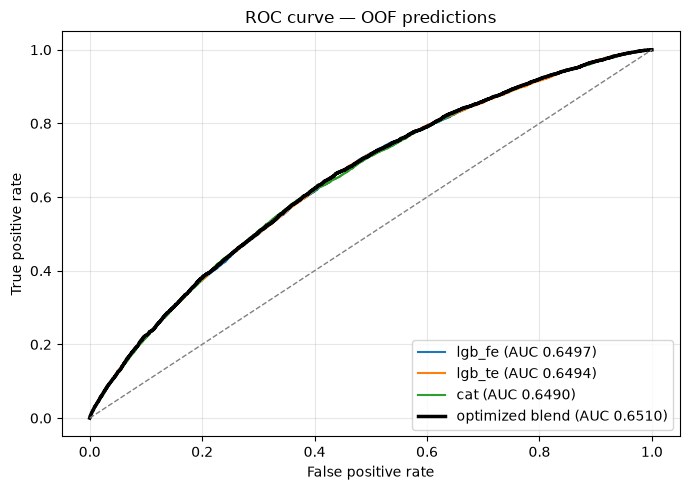

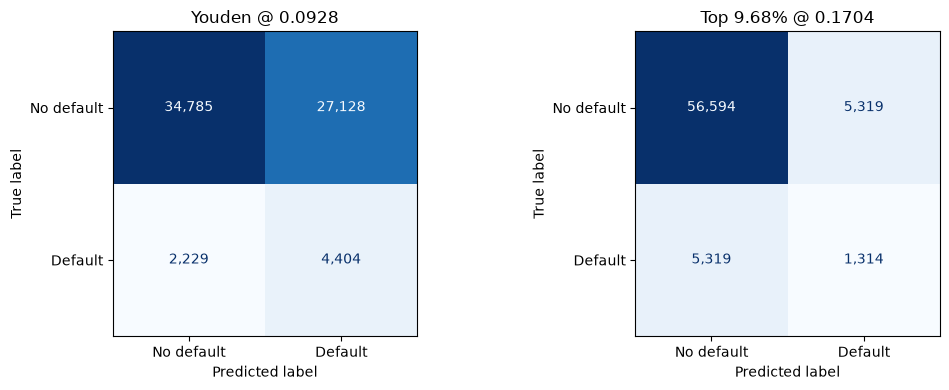

,threshold,cut,precision,recall,f1,balanced_accuracy
0,Youden,0.0928,0.1397,0.6640,0.2308,0.6129
1,Top rate,0.1704,0.1981,0.1981,0.1981,0.5561


In [21]:
print("Model results")
display(model_table.round(5).reset_index(drop=True))

print("Blend results")
display(blend_table.round(5).reset_index(drop=True))
print("Chosen blend:", chosen_name, "| weights:", chosen["weights"])

importance_frames = []
for name, result in results.items():
    if result.feature_importance is None:
        continue
    top = result.feature_importance.head(10).rename("importance").reset_index()
    top.columns = ["feature", "importance"]
    top.insert(0, "model", name)
    importance_frames.append(top)
if importance_frames:
    display(pd.concat(importance_frames, ignore_index=True))

submission_preview = data.template[["ID"]].merge(
    pd.DataFrame(
        {"ID": data.test_ids.to_numpy(), TARGET: test_calibrated}
    ),
    on="ID",
    how="left",
)
display(submission_preview.head())
print(f"submission rows: {len(submission_preview):,}")
print(f"missing predictions: {int(submission_preview[TARGET].isna().sum())}")

fig, ax = plt.subplots(figsize=(7, 5))
for name, result in results.items():
    fpr_i, tpr_i, _ = roc_curve(data.y, result.oof)
    ax.plot(
        fpr_i,
        tpr_i,
        lw=1.5,
        label=f"{name} (AUC {roc_auc_score(data.y, result.oof):.4f})",
    )
fpr_b, tpr_b, _ = roc_curve(data.y, chosen["oof"])
ax.plot(
    fpr_b,
    tpr_b,
    lw=2.5,
    color="black",
    label=f"{chosen_name} blend (AUC {roc_auc_score(data.y, chosen['oof']):.4f})",
)
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
ax.set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="ROC curve — OOF predictions",
)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, threshold) in zip(
    axes,
    [
        ("Youden", youden_threshold),
        (f"Top {data.y.mean():.2%}", oof_rate_threshold),
    ],
):
    labels = (oof_calibrated >= threshold).astype(int)
    cm = confusion_matrix(data.y, labels, labels=[0, 1])
    ConfusionMatrixDisplay(
        cm,
        display_labels=["No default", "Default"],
    ).plot(ax=ax, cmap="Blues", values_format=",d", colorbar=False)
    ax.set_title(f"{label} @ {threshold:.4f}")
plt.tight_layout()
plt.show()

threshold_rows = []
for label, threshold in (
    ("Youden", youden_threshold),
    ("Top rate", oof_rate_threshold),
):
    labels = (oof_calibrated >= threshold).astype(int)
    threshold_rows.append(
        {
            "threshold": label,
            "cut": threshold,
            "precision": precision_score(data.y, labels, zero_division=0),
            "recall": recall_score(data.y, labels, zero_division=0),
            "f1": f1_score(data.y, labels, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(data.y, labels),
        }
    )
display(pd.DataFrame(threshold_rows).round(4))

## หมายเหตุ

- **Validation** ใน notebook นี้คือ OOF prediction จาก outer folds
- `optimized` blend เลือก weights จาก OOF ชุดเดียวกับที่รายงาน → ตัวเลขอาจเอียงขึ้นเล็กน้อย
- Calibration เป็น monotone → ROC-AUC ไม่เปลี่ยน แต่ probability ตีความง่ายขึ้น
- ถ้าต้องการเทียบกับ notebook เก่า ต้องรัน `N_FOLDS` และ `SEEDS` ให้เท่ากัน
- `FAST=True` ใช้ 3 folds, 1 seed, ES 100, bootstrap 200
- `SAVE=False` ใช้ตรวจโค้ดโดยไม่เขียนทับผลลัพธ์เดิม